# 图

输出到 `figures/`。先运行初始化格；其余各格只依赖它，顺序随意。
热图和方差曲线读 `results/` 下的 CSV；箱线图和散点图用初始化格里算好的主成分得分。
格式和分辨率由初始化格的 `FORMAT`、`DPI` 决定：png 按 `DPI` 输出位图；svg、pdf 是矢量图（放 LaTeX 用 pdf）。

In [1]:
import pandas as pd

from fmspace.analysis import l2, pca, zscore
from fmspace.data import load_metadata
from fmspace.extract import load_features
from fmspace.models import MODELS
from fmspace.paths import DATA_DIR, FEATURE_DIR, FIGURE_DIR, RESULT_DIR
from fmspace.plots import grade_boxplot, heatmap, pc_scatter, variance_curve

FORMAT, DPI = "png", 600

metadata = load_metadata(DATA_DIR)
y = metadata["eye_dr_level"].to_numpy()
pcs, ratios = {}, {}  # 各模型的主成分得分、贡献率
for name in MODELS:
    X = l2(load_features(FEATURE_DIR / f"{name}.npz", metadata["image_id"]))
    p = pca(X)
    pcs[name], ratios[name] = p.transform(X), p.explained_variance_ratio_
pc1 = {n: zscore(pcs[n][:, 0], y) for n in MODELS}  # PC1 得分，z-score，方向调成与 DR 正相关

c:\M1\envs\fmspace\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## PC × 标签热图

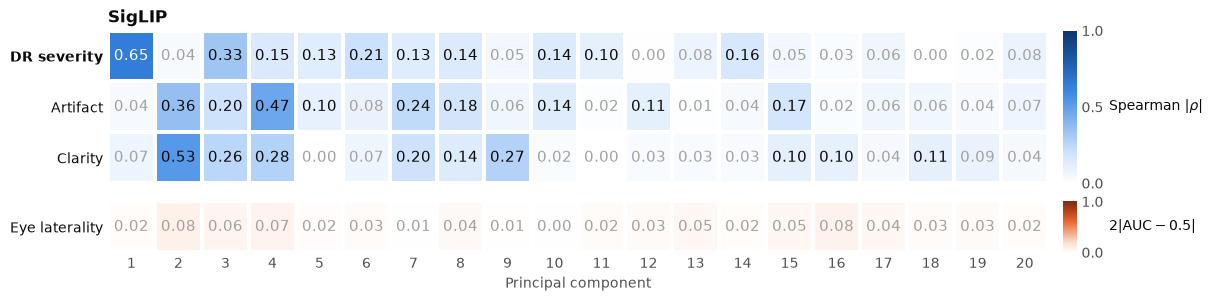

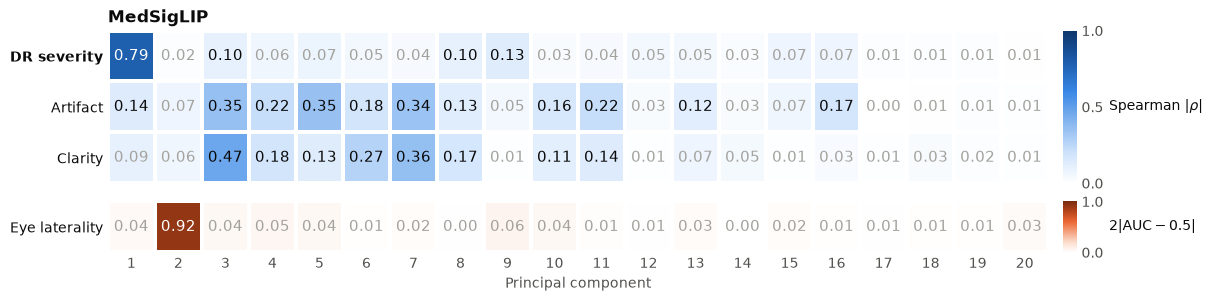

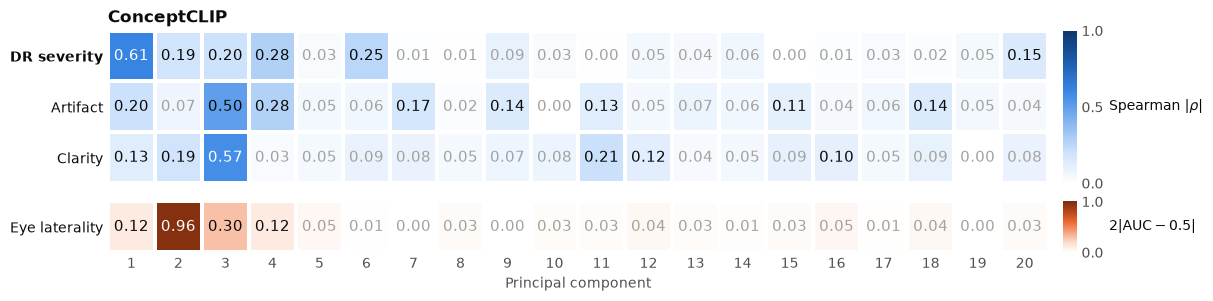

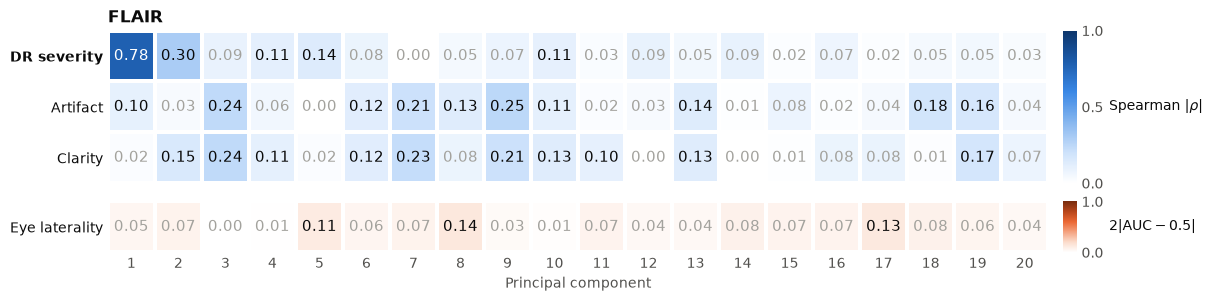

In [2]:
assoc = pd.read_csv(RESULT_DIR / "pc_association.csv")
for name in MODELS:
    fig = heatmap(assoc, name, ["eye_dr_level", "artifact", "clarity", "eye"])
    fig.savefig(FIGURE_DIR / f"heatmap_{name}.{FORMAT}", bbox_inches="tight", dpi=DPI)

## 累计解释方差

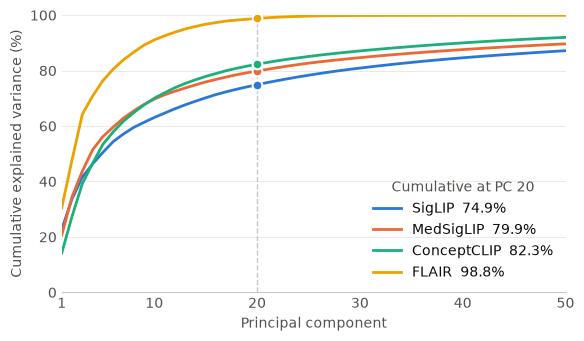

In [3]:
variance = pd.read_csv(RESULT_DIR / "explained_variance.csv")
fig = variance_curve(variance, list(MODELS), n_pcs=50, mark=20)
fig.savefig(FIGURE_DIR / f"variance_cumulative.{FORMAT}", bbox_inches="tight", dpi=DPI)

## 各等级在 PC1 上的箱线图（4 个模型并排）

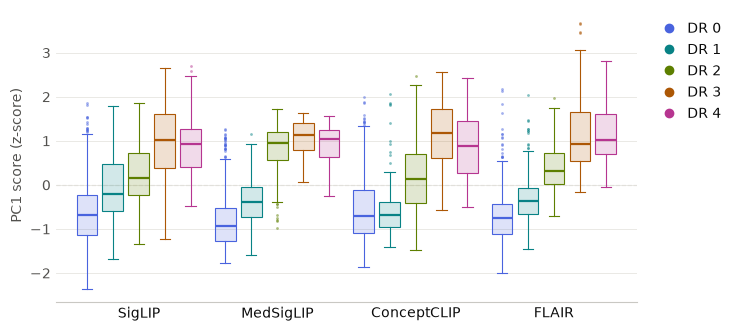

In [4]:
fig = grade_boxplot(pc1, y, list(MODELS))
fig.savefig(FIGURE_DIR / f"boxplot_pc1.{FORMAT}", bbox_inches="tight", dpi=DPI)

## 第 1、2 主成分的散点图

全部 1,189 张。颜色为 DR 等级，实心为左眼、空心为右眼；纵横同比例，轴标签里是贡献率。

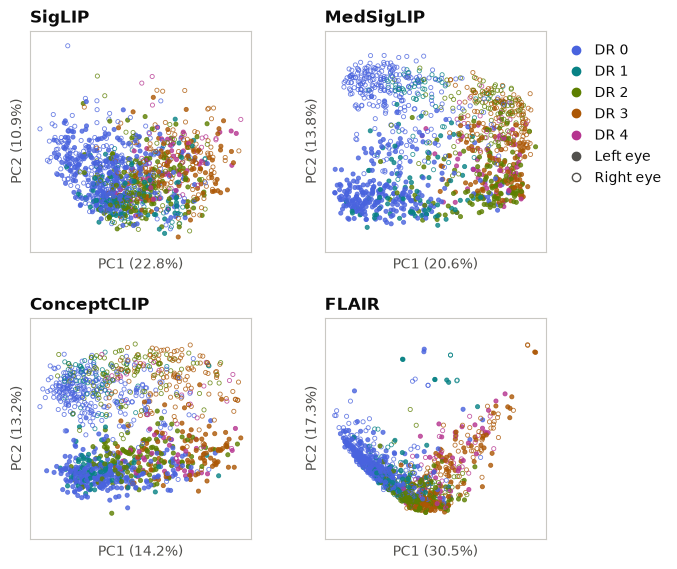

In [5]:
fig = pc_scatter(pcs, ratios, y, metadata["eye"].to_numpy(), list(MODELS), ncols=2)
fig.savefig(FIGURE_DIR / f"pc12_scatter.{FORMAT}", bbox_inches="tight", dpi=DPI)